# Chicken counting with a UNet

Count chickens in farm images (IOAI 2025 task). I built a U-Net style decoder on top of the provided pretrained feature extractor to predict a density map and summed it to get the count. Got 0.829 with the evaluate function on the training data.

# Chicken Counting

## **1. Problem Description**

Your team has access to a pretrained feature extractor for Silkie chicken images, but you'll need to design and train the density estimation decoder to create a complete counting solution. Your task is to build upon this foundation by developing an effective decoder architecture and training strategy to achieve accurate chicken counts that farmers and insurance companies can rely on.

## **3. Task**

Your task is to train your own model using the training data to predict density maps, thereby serving the purpose of chicken counting.

## **5. Scoring**

You will be scored based on the mean relative error of your model. Relative error is defined by:

$$
\text{Relative Error} = \frac{|y_i - \hat{y}_i|}{|y_i|}
$$

where $y_i$ is the true total density for the $i$-th sample, and $\hat{y}_i$ is the predicted total density for the $i$-th sample.

Your final score before normalization will be calculated based on your mean relative error, as follows:

$$
\text{Score} = \exp(-\frac{1}{n} \sum_{i=1}^{n} \frac{|y_i - \hat{y}_i|}{y_i})
$$

- The highest score by the Scientific Committee for this task is 0.89,  this score is used for score unification.
- The baseline score by the Scientific Committee for this task is 0.71, this score is used for score unification.

### Imports

In [1]:
import random
import numpy as np
import torch

seed = 42

random.seed(seed)                  # Python built-in random
np.random.seed(seed)               # NumPy
torch.manual_seed(seed)            # PyTorch (CPU)
torch.cuda.manual_seed(seed)       # PyTorch (single GPU)
torch.cuda.manual_seed_all(seed)   # PyTorch (all GPUs)

# Ensures deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [2]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from datasets import load_from_disk
import logging
from tqdm import tqdm
import numpy as np
import math

#Contestants should mount "counting_problem_train(v1)" datasets while creating the node.
TRAIN_PATH = "/bohr/train-adnz/v1/"  #Address of the training set and base.pth
# The training set is deployed automatically in the testing machine.
# You notebook can access the TRAIN_PATH even if you do not mount it along with notebook.
TRAINING_SET = TRAIN_PATH + "train" #Address of the traninig set
BASE_MODEL_PATH = TRAIN_PATH + "base.pth"#Address of the .pth file
DTYPE = torch.float32
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
scale = 100.0

In [3]:
from datasets import load_dataset

train_dataset = load_dataset("ioaihsc/Task2_Chicken_Counting_Train2",
                            data_dir="train",
                            split="train")

### Logging Utilities

In [4]:
def logging_level(level='info'):
    str_format = '%(asctime)s - %(levelname)s: %(message)s'
    if level == 'debug':
        logging.basicConfig(level=logging.DEBUG, format=str_format, datefmt='%Y-%m-%d %H:%M:%S')
    elif level == 'info':
        logging.basicConfig(level=logging.INFO, format=str_format, datefmt='%Y-%m-%d %H:%M:%S')
    return logging


class BatchLossLogger:
    def __init__(self, log_interval=100):
        self.losses = []
        self.batch_number = 0
        self.log_interval = log_interval

    def log(self, loss):
        self.losses.append(loss)
        self.batch_number += 1
        if self.batch_number % self.log_interval == 0:
            logging.info(f'Batch No. {self.batch_number:7d} - loss: {loss:.6f}')

### Training Your Model
#### Model Definition
Pretrained weights of the `FeatureExtraction` model is provided in `base.pth` in the training set, along with a function to load them.
`ChickenCounting` is the completed model.

In [5]:
save_model = torch.load("/content/base.pth")

In [6]:
import torch.nn.functional as F

class DoubleConv(nn.Module):
  def __init__(self, in_channels, out_channels):
    super(DoubleConv, self).__init__()
    self.conv = nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size = 3, padding = 1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        #nn.Dropout(p=0.1),
        nn.Conv2d(out_channels, out_channels, kernel_size = 3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU()
    )
  def forward(self, X):
    return self.conv(X)

class UpSample(nn.Module):
  def __init__(self, in_skip, in_channels, out_channels):
    super(UpSample, self).__init__()
    self.Transpose = nn.ConvTranspose2d(in_channels, in_skip, kernel_size = 4, stride = 2, padding = 1)
    self.conv_main = DoubleConv(in_skip*2, out_channels)
  def forward(self, X_skip, X_last):
    X_last = self.Transpose(X_last)
    return self.conv_main(torch.cat([X_skip, X_last], axis=1))

class UNET(nn.Module):
  def __init__(self, in_channels=128, out_channels=1):
    super(UNET, self).__init__()

    self.conv1 = DoubleConv(in_channels, 128) ## 2128 channels
    self.conv2 = DoubleConv(128, 256) ## 256 channels
    self.conv3 = DoubleConv(256, 512) ## 512 channels

    self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    self.bottleneck = DoubleConv(512, 1024) # 1024 channels

    self.conv3_t = UpSample(512, 1024, 512)
    self.conv2_t = UpSample(256, 512, 256)
    self.conv1_t = UpSample(128, 256, 128)

    self.final = nn.Conv2d(in_channels = 128, out_channels = 1, kernel_size = 1, stride = 1)

  def forward(self, X):

    X = F.interpolate(
        X, size = (176, 320), mode = 'bilinear', align_corners = False
    )

    x1 = self.conv1(X)
    x2 = self.conv2(self.pool(x1))
    x3 = self.conv3(self.pool(x2))

    bottle = self.bottleneck(self.pool(x3))

    z3 = self.conv3_t(x3, bottle)
    z2 = self.conv2_t(x2, z3)
    z1 = self.conv1_t(x1, z2)

    last = self.final(z1)

    last = F.interpolate(
        last, size = (180, 320), mode = 'bilinear', align_corners = True
    )

    return last

In [7]:
class FeatureExtraction(nn.Module):
    def __init__(self, in_channels=3):
        super(FeatureExtraction, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, 64, kernel_size=3, padding=2, dilation=2) ## same (180, 320)
        self.conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=2, dilation=2)

        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=2, dilation=2)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=2, dilation=2)

        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)


    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.pool4(x)

        return x

    def load_pretrained_weights_partial(self, weights_path, num_layers=4):
        save_model = torch.load("/content/base.pth")
        partial_state_dict = {}
        expected_layers = [
            'feature_extraction.conv1.weight', 'feature_extraction.conv1.bias',
            'feature_extraction.conv2.weight', 'feature_extraction.conv2.bias',
            'feature_extraction.conv3.weight', 'feature_extraction.conv3.bias',
            'feature_extraction.conv4.weight', 'feature_extraction.conv4.bias',
        ]
        state_dict = {k.split('.', 1)[-1]: v for k, v in save_model.items() if k in expected_layers[:2 * num_layers]}
        model_dict = self.state_dict()

        for k in state_dict:
            if k in model_dict:
                partial_state_dict[k] = state_dict[k]
                print(k)

        self.load_state_dict(partial_state_dict)


class ChickenCounting(nn.Module):
    def __init__(self):
        super(ChickenCounting, self).__init__()
        self.feature_extraction = FeatureExtraction()
        self.feature_decoder = UNET()

    def forward(self, x):
        x = self.feature_extraction(x)
        x = self.feature_decoder(x)
        #return F.relu(x)
        logits = F.relu(x)
        return logits

In [8]:
model = ChickenCounting()
model.to('cuda')

ChickenCounting(
  (feature_extraction): FeatureExtraction(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), dilation=(2, 2))
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), dilation=(2, 2))
    (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), dilation=(2, 2))
    (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), dilation=(2, 2))
    (pool4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (feature_decoder): UNET(
    (conv1): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNo

### Reading the Dataset
Read the train dataset

In [9]:
#train_dataset = load_from_disk(TRAINING_SET)

import torchvision.transforms.v2 as v2
from torch.utils.data import RandomSampler

image_transform = v2.Compose([
    v2.ToTensor(),
])

def collate_fn(batch, scale = scale):
    return {
        "image": torch.stack([image_transform(item["image"]) for item in batch]),
        "density": torch.stack([torch.tensor(item["density"], dtype=DTYPE).unsqueeze(0) * scale for item in batch]) # Multiply by scale for faster training
    }

limited_sampler = RandomSampler(train_dataset, num_samples=20, replacement=True)


train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(train_dataset, batch_size=1, shuffle=False, collate_fn=collate_fn, sampler = limited_sampler)

/usr/local/lib/python3.12/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


### Run Training

In [10]:
import matplotlib.pyplot as plt
import numpy as np


def plot(density_map):
    density_map = np.squeeze(density_map.cpu().numpy())

    # Debugging text to see if anything is alive
    print(f"--- Map Stats --- Max: {density_map.max():.4f} | Total predicted count: {density_map.sum():.2f}")

    fig, ax = plt.subplots(figsize=(6, 6))
    # Bound vmax to at least 0.01 so if the map is all 0, it doesn't break the colormap
    cax = ax.imshow(density_map, cmap='viridis', vmin=0.0, vmax=density_map.max())

    cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Density Prediction')

    ax.set_title('U-Net Density Map')
    ax.axis('off')

    # Force the notebook to display it inside loops
    display(fig)
    plt.close(fig)

In [11]:
import torch.nn as nn
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        # Flatten the tensors
        #pred = torch.sigmoid(pred)
        #target = torch.sigmoid(target)

        pred = pred.view(-1)
        target = target.view(-1)

        # Calculate intersection
        intersection = (pred * target).sum()

        # Dice formula
        dice = (2. * intersection + self.smooth) / (pred.sum() + target.sum() + self.smooth)

        return 1 - dice

class CountingLoss(nn.Module):
    def __init__(self):
        super(CountingLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.dice = DiceLoss()

    def forward(self, pred, target):
        # MSE for count accuracy
        loss_mse = self.mse(pred, target)
        # Dice for shape/spatial accuracy
        loss_dice = self.dice(pred, target)

        return loss_mse + loss_dice

In [14]:
#Definition of the training process
import time
from IPython.display import clear_output
def train_chickenfcn(criterion, model, train_loader, val_loader, optimizer, scheduler, num_epochs, device, save_path):
    model.train()
    criterion_mse = torch.nn.MSELoss(reduction='sum').to(device)
    criterion_mae = torch.nn.L1Loss(reduction='sum').to(device)
    #criterion_cross = torch.nn.CrossEntropyLoss(weight = torch.tensor([1.0, 8.0]))
    best_loss = float('inf')
    print(train_loader.__len__())

    for epoch in range(num_epochs):

        train_loss_mse = 0.0
        train_loss_mae = 0.0

        train_loader_tqdm = tqdm(train_loader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False)

        for i, data in enumerate(train_loader_tqdm, 0):
            inputs, targets = data["image"], data["density"]
            inputs = inputs.to(device).float()
            targets = targets.to(device).float()
            # print(targets.shape)
            # t = np.sum((targets[0] / scale).cpu().numpy().squeeze())
            # print(t)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss_mse = criterion_mse(outputs, targets)
            loss_mae = criterion_mae(outputs, targets)
            #loss_cross = criterion_cross(outputs, targets)
            #comb_loss = loss_mse + loss_mae
            #lossy = criterion(outputs, targets)
            loss_mae.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)

            optimizer.step()
            train_loss_mse += loss_mse.item()
            train_loss_mae += loss_mae.item()

            train_loader_tqdm.set_postfix({'Train MSE Loss': loss_mse.item(), 'Train MAE Loss': loss_mae.item()})

        train_loss_mse /= (len(train_loader))
        train_loss_mae /= (len(train_loader))
        logging.info(
            f'Epoch [{epoch + 1}/{num_epochs}], Train MSE loss: {train_loss_mse:.8f}, MAE loss: {train_loss_mae:.8f}')

        scheduler.step()

        # Validation
        model.eval()
        val_loss_mse = 0.0
        val_loss_mae = 0.0

        val_loader_tqdm = tqdm(val_loader, desc=f'Validation Epoch {epoch + 1}/{num_epochs}', leave=False)

        with torch.no_grad():
            for i, data in enumerate(val_loader_tqdm, 0):
                inputs, targets = data["image"], data["density"]
                inputs = inputs.to(device).float()
                targets = targets.to(device).float()

                outputs = model(inputs)

                if i == len(val_loader) - 1:
                    clear_output(wait=True)  # Keeps the notebook output clean epoch-to-epoch
                    plot(outputs.detach())
                    time.sleep(1.0)

                mse_loss = criterion_mse(outputs, targets)
                mae_loss = criterion_mae(outputs, targets)
                val_loss_mse += mse_loss.item()
                val_loss_mae += mae_loss.item()

                val_loader_tqdm.set_postfix(
                    {'Validation MSE Loss': mse_loss.item(), 'Validation MAE Loss': mae_loss.item()})

        val_loss_mse /= (len(val_loader))
        val_loss_mae /= (len(val_loader))
        logging.info(
            f'Epoch [{epoch + 1}/{num_epochs}], Validation MSE Loss: {val_loss_mse:.8f}, MAE Loss: {val_loss_mae:.8f}')

        # Save Model
        if val_loss_mae < best_loss:
            best_loss = val_loss_mae
            torch.save(model.state_dict(), save_path)

    print('Finished Training ChickenFCN')

--- Map Stats --- Max: 0.0000 | Total predicted count: 0.00


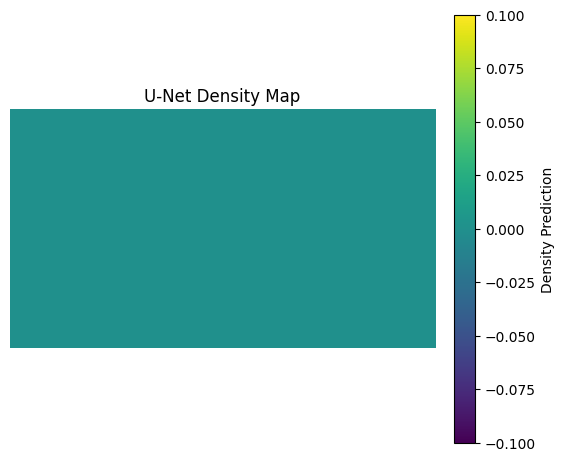

In [15]:
logging = logging_level('info')
logging.debug('use debug level logging setting')

################################################################################
# Experiment Settings
################################################################################
learning_rate = 1e-4
lr_decay = 1e-5
weight_decay = 0.0001
save_path = "model.pth"

epochs = 20

# Training
crit = CountingLoss()
model = ChickenCounting().to(DEVICE)
model.feature_extraction.load_pretrained_weights_partial('/content/base.pth')
print('load model success')

optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size = 1, gamma=1 - lr_decay)

logging.info('Begin training single view model...')
train_chickenfcn(crit, model, train_loader, val_loader, optimizer, scheduler, epochs, DEVICE, save_path=save_path)
logging.info('Finished training single view model.')

### Evaluate Model
This section validates the model on the train set, which helps contestants understand whether the model is usable and calculate the score on the train set.

In [89]:
# Definition of the evaluation function
def evaluate(model, val_loader, device, scale): # Function used for final scoring.
    model.eval()  # Set the model to evaluation mode

    # Initialize metrics
    mse = 0.0
    mae = 0.0
    predict_num = 0.0
    true_num = 0.0
    rate = 0.0

    with torch.no_grad():  # Disable gradient calculation for inference
        for i, data in enumerate(val_loader, 0):
            inputs, targets = data["image"], data["density"]
            inputs = inputs.to(device).float()  # Move inputs to device and convert to float
            targets = targets.to(device).float()  # Move targets to device and convert to float

            # Get the model predictions
            outputs = model(inputs) / scale  # Adjusting for the scaling factor

            # Convert tensors to numpy for visualization and metrics calculation
            inputs_np = inputs.cpu().numpy()  # Convert inputs to numpy
            targets_np = targets.cpu().numpy()  # Convert targets to numpy
            outputs_np = outputs.cpu().numpy()  # Convert outputs to numpy
            # imshow_res(inputs_np, targets_np, outputs_np, scale)  # Uncomment to visualize results

            # Calculate true and predicted sums for comparison
            t = np.sum((targets[0] / scale).cpu().numpy().squeeze())  # Ground truth sum
            g = np.sum(outputs.cpu().numpy().squeeze())  # Predicted sum
            print(f'NO.{i}   true_sum={t}, get_sum={g}, abs={abs(t - g)}, rate={abs(1 - g / t)}')

            # Update metrics
            predict_num += g
            true_num += t
            rate += abs(1 - g / t)
            mae += abs(t - g)
            mse += abs(t - g) * abs(t - g)

    # Calculate average metrics across all batches
    mae /= len(val_loader)
    mse /= len(val_loader)
    predict_num /= len(val_loader)
    true_num /= len(val_loader)
    rate /= len(val_loader)

    # Log the results
    logging.info(
        f'test ---- Score: {math.exp(-rate):.3f}, MSE: {mse:.4f}, MAE: {mae:.4f}, Chicken_avg: {predict_num:.4f}')
    return math.exp(-rate)

In [90]:
model.load_state_dict(torch.load(save_path, map_location=DEVICE))
model.to(DEVICE)
evaluate(model, val_loader, DEVICE, scale)

NO.0   true_sum=29.792863845825195, get_sum=33.15071487426758, abs=3.357851028442383, rate=0.11270654201507568
NO.1   true_sum=39.4925537109375, get_sum=40.34604263305664, abs=0.8534889221191406, rate=0.021611332893371582
NO.2   true_sum=14.767253875732422, get_sum=15.706815719604492, abs=0.9395618438720703, rate=0.06362473964691162
NO.3   true_sum=16.0, get_sum=17.87281036376953, abs=1.8728103637695312, rate=0.1170506477355957
NO.4   true_sum=57.181270599365234, get_sum=41.481658935546875, abs=15.69961166381836, rate=0.2745586633682251
NO.5   true_sum=21.92753791809082, get_sum=13.161949157714844, abs=8.765588760375977, rate=0.39975255727767944
NO.6   true_sum=24.663095474243164, get_sum=33.91829299926758, abs=9.255197525024414, rate=0.3752650022506714
NO.7   true_sum=18.76982307434082, get_sum=19.078115463256836, abs=0.3082923889160156, rate=0.016424894332885742
NO.8   true_sum=24.960134506225586, get_sum=12.745131492614746, abs=12.21500301361084, rate=0.48938047885894775
NO.9   true

0.8290040162554972

### Submission
This part is to generate the result files for testing and scoring.
Contestants couldn't access the validation set(test_a) and the test set(test_b) locally.
Please read through the following code carefully. Make sure to following the file naming conventions.

In [91]:
from datasets import load_dataset
import torchvision.transforms as transforms

image_transform = transforms.Compose([
    transforms.ToTensor(),
])

def collate_fn(batch, scale=scale):
    return {
        "image": torch.stack([image_transform(item["image"]) for item in batch]),
        "density": torch.stack([torch.tensor(item["density"], dtype=DTYPE).unsqueeze(0) * scale for item in batch])
    }

test_dataset = load_dataset("ioaihsc/Task2_Chicken_Counting_Test",
                            data_dir="valandtest",
                            split="validation")

def collate_fn(batch): # The test datasets will not provide target densities
    return torch.stack([image_transform(item["image"]) for item in batch])

test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, collate_fn=collate_fn)

predictions = []
model.eval()
with torch.no_grad():
    for batch in tqdm(test_loader):
        outputs = model(batch.to(DEVICE)) / scale
        predictions.append(outputs.cpu().numpy())

pred_a = np.concatenate(predictions, axis=0)

del test_dataset
del test_loader
del predictions

test_dataset = load_dataset("ioaihsc/Task2_Chicken_Counting_Test",
                            data_dir="valandtest",
                            split="test")
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, collate_fn=collate_fn)

predictions = []
with torch.no_grad():
    for batch in tqdm(test_loader):
        outputs = model(batch.to(DEVICE)) / scale
        predictions.append(outputs.cpu().numpy())

pred_b = np.concatenate(predictions, axis=0)

np.savez('submission.npz', pred_a=pred_a, pred_b=pred_b) # save your submissions in `submission.npz` file with the keys `pred_a` and `pred_b`

README.md:   0%|          | 0.00/446 [00:00<?, ?B/s]

valandtest/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  167MB            

valandtest/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

valandtest/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  168MB            

valandtest/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

100%|██████████| 7/7 [00:07<00:00,  1.14s/it]


In [92]:
!python /content/metrics.py